# R6 · Breast block programmes (Supplementary Fig S2) and within-platform queries (Fig 3C)

For the breast section, this notebook computes:

* **Programmes**, on the whole-section build (`full`: every tile indexed, the layout is built here). For each
  niche × block it records co-variation within the block, between the block and the rest of the niche, and against random gene sets, plus
  hub genes, Hallmark / GO BP enrichment, the niches' cell types and ACTA2's partners.
* **Queries**, on seed 0: every held-out tile as a whole-tile query (Spindle's top 10 and top 5 against a random 10 and 5, by cell composition; Spindle-naive's for reference),
  with an example query.

The definitions and pre-registered rules are in `experiments/common/programs.py`.

* **Prerequisites:** `R0_index_cache` (breast_cancer builds and staged inputs), plus the Enrichr GMT files in `~/.cache/gseapy/`
  (MSigDB Hallmark 2020, GO Biological Process 2023).
* **Writes:** `results/breast_programs/full/` (`blocks.csv`, `enrich_null.csv`, `niche_types.csv`, `acta2.csv`, `corr_niche<k>.npy`,
  `layout.json`, `cells_niche.npz`) and `results/breast_programs/seed0/` (`tile_queries.csv`, `example.csv`, `example_cells.npz`).
* **Skips** a build whose outputs exist (`FORCE = True` redoes them).
* **Runtime / memory:** a few minutes; peak about 3 GB.

In [1]:
import gc
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import data
import programs as pg
import results_io as rio
import sections as sx

FORCE = False
TOPIC = "breast_programs"
BUILD = "full"
SEED = data.EXAMPLE_SEED
print(data.stamp())


def sub(build):
    return "full" if build == "full" else f"seed{build}"


def done(build, names):
    return not FORCE and all((rio.topic(TOPIC) / sub(build) / n).exists() for n in names)


def save_arrays(build, name, arrays, description):
    path = rio.topic(TOPIC) / sub(build) / name
    np.savez_compressed(path, **arrays)
    rio.register(TOPIC, path, description)


DESC = {
    "blocks": "one row per niche x block: genes, hubs, within / between / null mean |r|, null_p, co-varying, enrichment",
    "enrich_null": "expected enriched fraction of random gene sets per block size",
    "niche_types": "annotated cell types of each niche's index-tile cells vs the section",
    "acta2": "r of ACTA2 with every gene per niche, and whether the gene is in ACTA2's block",
    "tile_queries": "one row per held-out tile: class composition, TV to Spindle's top 10 / top 5, random 10 / random 5, Spindle-naive's top 10 / top 5; Spindle's overlap with Spindle-naive's 10, tiles returned",
    "example": "the example whole-tile query (rule in programs.py): compositions of query, Spindle's top 10, random 10, section, Spindle's top 5, random 5",
}

{'tag': 'method-v2', 'describe': 'method-v3-dirty', 'commit': 'b35f7d4'}


## Programmes (`full`)

In [2]:
PROG = ["blocks.csv", "enrich_null.csv", "niche_types.csv", "acta2.csv"]
if done(BUILD, PROG):
    print(f"{BUILD}: programmes exist, skipped")
else:
    S = sx.load(pg.KEY, BUILD, parts=pg.PROGRAM_PARTS)
    out = pg.programs(S, BUILD)
    (rio.topic(TOPIC) / sub(BUILD)).mkdir(exist_ok=True)
    for name in ("blocks", "enrich_null", "niche_types", "acta2"):
        rio.write_csv(out[name], TOPIC, f"{sub(BUILD)}/{name}.csv", DESC[name])
    for k, R in out["corr"].items():
        path = rio.topic(TOPIC) / sub(BUILD) / f"corr_niche{k}.npy"
        np.save(path, R)
        rio.register(TOPIC, path, f"niche {k}'s mean correlation in its gene order (float32)")
    path = rio.topic(TOPIC) / sub(BUILD) / "layout.json"
    path.write_text(json.dumps(out["layout"]))
    rio.register(TOPIC, path, "gene order and blocks per niche, panel genes")
    save_arrays(BUILD, "cells_niche.npz", out["cells_niche"], "every cell: x, y, its tile's niche (-1 = none)")
    del S, out
    gc.collect()

full: programmes exist, skipped


### Summary: co-varying and enriched blocks per niche

In [3]:
summ = []
B = pd.read_csv(rio.topic(TOPIC) / sub(BUILD) / "blocks.csv")
for k, b in B.groupby("niche"):
    summ.append({"build": sub(BUILD), "niche": k + 1, "tiles": b.n_tiles.iloc[0], "blocks": len(b),
                 "co-varying": int(b.covarying.sum()), "enriched": int(b.enriched.sum()),
                 "both": int((b.covarying & b.enriched).sum()), "within (median)": b.within.median(),
                 "between (median)": b.between.median(), "random (median)": b.null_mean.median()})
pd.DataFrame(summ).round(3)

,build,niche,tiles,blocks,co-varying,enriched,both,within (median),between (median),random (median)
0,full,1,760,16,8,6,6,0.063,0.027,0.038
1,full,2,757,17,7,3,3,0.041,0.027,0.037
2,full,3,527,15,6,3,3,0.038,0.023,0.032


### The whole-section build: co-varying blocks of the chosen niche (Supplementary Fig S2 rule: most blocks both co-varying and enriched)

In [4]:
B = pd.read_csv(rio.topic(TOPIC) / "full" / "blocks.csv")
g = B.assign(both=B.covarying & B.enriched).groupby("niche").agg(both=("both", "sum"), tiles=("n_tiles", "first"))
main = int(g.sort_values(["both", "tiles"], ascending=False).index[0])
print(f"chosen niche {main + 1}; contrast niche {int(g.drop(main).sort_values('tiles', ascending=False).index[0]) + 1}")
B[(B.niche == main) & B.covarying][["block", "size", "hubs", "within", "between", "null_p", "key_term", "key_fdr"]]

chosen niche 1; contrast niche 2


,block,size,hubs,within,between,null_p,key_term,key_fdr
6,6,15,AQP1 PECAM1 VWF,0.236704,0.024944,0.000999,NaN,NaN
8,8,15,CD3E PTPRC CCL5,0.166046,0.033773,0.000999,Allograft Rejection,1.187291e-02
9,9,18,APOC1 CXCL16 PDK4,0.086627,0.029647,0.007992,Microglial Cell Activation (GO:0001774),9.848025e-03
10,10,15,FCER1G LYZ CD4,0.325181,0.039561,0.000999,NaN,NaN
11,11,21,LUM POSTN CCDC80,0.215726,0.033443,0.000999,Epithelial Mesenchymal Transition,7.549027e-07
13,13,15,KRT14 MYLK KRT5,0.269348,0.038367,0.000999,Intermediate Filament Organization (GO:0045109),1.673546e-03
14,14,24,TOP2A RTKN2 PCLAF,0.101710,0.044788,0.000999,G2-M Checkpoint,3.492455e-04
15,15,57,ERBB2 EPCAM CEACAM6,0.258795,0.044047,0.000999,Androgen Response,3.116618e-02


## Queries (seed 0)

In [5]:
QUER = ["tile_queries.csv", "example.csv"]
if done(SEED, QUER):
    print(f"seed {SEED}: queries exist, skipped")
else:
    S = sx.load(pg.KEY, SEED, parts=pg.QUERY_PARTS)
    out = pg.tile_queries(S, SEED)
    for name in ("tile_queries", "example"):
        rio.write_csv(out[name], TOPIC, f"seed{SEED}/{name}.csv", DESC[name])
    save_arrays(SEED, "example_cells.npz", out["example_cells"], "cells (x, y, class) and boxes of the example query and Spindle's top 10")
    del S, out
    gc.collect()

seed 0: queries exist, skipped


### Summary: whole-tile queries (composition difference TV; lower = more alike)

,queries,tv_spindle,tv_random,tv_spindle5,tv_random5,tv_naive5,spindle_in_naive,found_below5,below_random,below_random5
0,204,0.156,0.531,0.153,0.543,0.123,3.0,5,0.975,0.975


     set  Invasive tumour  DCIS  Myoepithelial  Stromal  Endothelial / perivascular  Myeloid  T cells  B cells
   query            0.000 0.138          0.359    0.349                       0.021    0.082    0.036    0.015
   top10            0.000 0.123          0.369    0.341                       0.030    0.096    0.033    0.009
random10            0.247 0.170          0.065    0.250                       0.061    0.085    0.092    0.030
 section            0.243 0.155          0.062    0.264                       0.061    0.086    0.097    0.031
    top5            0.000 0.148          0.390    0.298                       0.042    0.092    0.025    0.006
 random5            0.244 0.166          0.069    0.250                       0.058    0.085    0.097    0.030


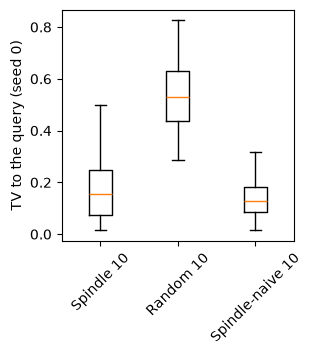

In [6]:
T = pd.read_csv(rio.topic(TOPIC) / f"seed{SEED}" / "tile_queries.csv")
display(pd.DataFrame([{"queries": len(T), "tv_spindle": T.tv_spindle.median(), "tv_random": T.tv_random.median(),
                       "tv_spindle5": T.tv_spindle5.median(), "tv_random5": T.tv_random5.median(),
                       "tv_naive5": T.tv_naive5.median(), "spindle_in_naive": T.spindle_in_naive.median(),
                       "found_below5": int((T.spindle_found < 5).sum()),
                       "below_random": (T.tv_spindle < T.tv_random).mean(),
                       "below_random5": (T.tv_spindle5 < T.tv_random5).mean()}]).round(3))
print(pd.read_csv(rio.topic(TOPIC) / f"seed{SEED}" / "example.csv").iloc[:, :9].round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(3, 3))
ax.boxplot([T.tv_spindle.dropna(), T.tv_random, T.tv_naive], showfliers=False)
ax.set_xticks([1, 2, 3], ["Spindle 10", "Random 10", "Spindle-naive 10"], rotation=45)
ax.set_ylabel(f"TV to the query (seed {SEED})")
plt.show()

In [7]:
rio.write_manifest(TOPIC, "R6_breast_programs.ipynb", inputs=["results/_cache/breast_cancer", "~/.cache/gseapy"],
                   notes="Supplementary Fig S2 (full = whole-section layout, no tile held out) and Fig 3C (seed 0) inputs")

wrote results/breast_programs/manifest.json: 12 files; peak memory 0.18 GB


{'topic': 'breast_programs',
 'notebook': 'R6_breast_programs.ipynb',
 'date': '2026-11-05 09:44',
 'tag': 'method-v2',
 'describe': 'method-v3-dirty',
 'commit': 'b35f7d4',
 'inputs': ['results/_cache/breast_cancer', '~/.cache/gseapy'],
 'peak_rss_gb': 0.18,
 'notes': 'Supplementary Fig S2 (full = whole-section layout, no tile held out) and Fig 3C (seed 0) inputs',
 'files': {'full/acta2.csv': {'description': "r of ACTA2 with every gene per niche, and whether the gene is in ACTA2's block",
   'rows': 936,
   'bytes': 44683},
  'full/blocks.csv': {'description': 'one row per niche x block: genes, hubs, within / between / null mean |r|, null_p, co-varying, enrichment',
   'rows': 48,
   'bytes': 15546},
  'full/cells_niche.npz': {'description': "every cell: x, y, its tile's niche (-1 = none)",
   'rows': None,
   'bytes': 1108827},
  'full/corr_niche0.npy': {'description': "niche 0's mean correlation in its gene order (float32)",
   'rows': None,
   'bytes': 392004},
  'full/corr_niche1